!pip install numpy pandas scikit-learn matplotlib

# JEDI Logistic Regression Baseline

**Goal:** train the first production-realistic classifier for JEDI.

The model in this notebook predicts:

```text
applied = yes / no
```

We intentionally do **not** use personal score columns in this first model. Those scores are labels/signals you created during annotation. A future scraped job will not naturally have those personal scores unless another model predicts them first.

So this notebook answers:

> Can logistic regression learn my apply/no-apply decision from raw and standardized job fields?


## What Logistic Regression Is

Logistic regression is a linear classification model.

It does not output a continuous score directly like normal linear regression. Instead, it learns a weighted sum of features and converts that value into a probability using the logistic/sigmoid function.

Conceptually:

```text
job features -> weighted sum -> probability of applied=yes
```

Example intuition:

```text
+ entry_level              increases probability
+ bengaluru                increases probability
+ backend/fullstack        increases probability
- senior/staff/principal   decreases probability
- remote global senior     decreases probability
```

Why it is a good first model:

- easy to explain
- works well with one-hot encoded categories
- works well with TF-IDF text features
- gives probabilities with `predict_proba`
- coefficients can be inspected to see which features push toward yes/no

Important limitation:

Logistic regression learns mostly linear patterns. If your preference depends on complex combinations, later models like tree ensembles or gradient boosting may perform better.

## Syntax Map To Remember

Most scikit-learn training code follows this pattern:

```python
X = df[feature_columns]
y = df[target_column]

X_train, X_test, y_train, y_test = train_test_split(...)

model = Pipeline([...])
model.fit(X_train, y_train)

predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]
```

Memory hook:

```text
split -> build pipeline -> fit -> predict -> evaluate
```

In [4]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    precision_recall_curve,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 140)

RANDOM_STATE = 42
DATA_PATH = Path("../../data/jedi_master_prepared.csv")
DATA_PATH

WindowsPath('../../data/jedi_master_prepared.csv')

## 1. Load The Prepared Dataset

We use `data/jedi_master_prepared.csv`, not the raw labeled file.

The prepared file already contains normalized fields like:

- `role_family_standard`
- `seniority_standard`
- `employment_type_standard`
- `work_mode_standard`
- `location_bucket`
- `skills_array`
- location flags
- salary and experience helper columns


In [5]:
df = pd.read_csv(DATA_PATH)

print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")
display(df.head(3))

display(pd.DataFrame({
    "column": df.columns,
    "dtype": [df[c].dtype for c in df.columns],
    "missing": [df[c].isna().sum() for c in df.columns],
    "unique": [df[c].nunique(dropna=True) for c in df.columns],
}))

Rows: 331
Columns: 51


,row_id,source_platform,source_type,scraped_at,can_apply_now,company_name,company_match_score,role_title,role_title_preference_score,role_family,role_family_preference_score,seniority,seniority_profile_fit_score,location,location_profile_fit_score,work_mode,work_mode_fit_score,employment_type,experience_min_years,experience_max_years,experience_profile_fit_score,skills_or_requirements,skills_profile_fit_score,salary_min,salary_max,salary_profile_fit_score,freshness,overall_preference_score,preference_reason,applied,apply_url,skills_or_requirements_original,skills_array,has_skills_or_requirements,skills_imputation_type,role_family_standard,seniority_standard,employment_type_standard,work_mode_standard,city_standard,country_standard,location_bucket,is_bengaluru,is_gurgaon_ncr,is_india,experience_min_bucket,salary_midpoint,salary_available,near_duplicate_key,company_name_standard,role_title_standard
0,1,Greenhouse,deterministic_scrape_candidate,27-06-2026,Yes,Nirmata,4,"Software Engineer Intern, India",5,Backend / Cloud,4,intern,5,"Bangalore, Hybrid",4,Hybrid,5,internship,0.0,1.0,5.0,Go; Java; microservices; Kubernetes; Prometheus; TimeScale; reliability; automation,2,1200000,1200000,5,Not visible,3,"Intern role is fine, everything is good but the requirements state Kubernetes, observability tools, promethus and Go which dont match wi...",no,https://job-boards.greenhouse.io/nirmata/jobs/5040355008,Go; Java; microservices; Kubernetes; Prometheus; TimeScale; reliability; automation,"[""go"",""java"",""microservices"",""kubernetes"",""prometheus"",""timescale"",""reliability"",""automation""]",True,original,backend,intern,internship,hybrid,bengaluru,india,bengaluru,True,False,True,0,1200000,True,nirmata|software_engineer_intern_india|bengaluru,nirmata,software_engineer_intern_india
1,2,Greenhouse,deterministic_scrape_candidate,27-06-2026,Yes,CloudSEK,5,SDE - Backend - Intern,5,Backend,5,intern,5,"Bengaluru, Karnataka, India",4,Hybrid,5,internship,0.0,1.0,5.0,Backend engineering; cybersecurity product; APIs; databases likely,4,800000,900000,4,Not visible,4,"Backend intern in Bengaluru; very relevant for fresher profile, salary is a little less and location bengaluru",yes,https://job-boards.greenhouse.io/cloudsek/jobs/5766402004,Backend engineering; cybersecurity product; APIs; databases likely,"[""backend engineering"",""cybersecurity product"",""apis"",""databases likely""]",True,original,backend,intern,internship,hybrid,bengaluru,india,bengaluru,True,False,True,0,850000,True,cloudsek|sde_backend_intern|bengaluru,cloudsek,sde_backend_intern
2,3,Greenhouse,deterministic_scrape_candidate,27-06-2026,Yes,Anaplan,5,Associate Software Engineer,5,Backend / Fullstack,5,entry_level,5,"Gurugram, India",5,unknown,5,full_time,0.0,2.0,5.0,Software engineering; AI-infused platform; SaaS; cloud; planning systems,5,500000,700000,2,Not visible,3,Associate level in Gurgaon; high-quality company and location fitbut salary is quite less and the bad factor,yes,https://job-boards.greenhouse.io/anaplan/jobs/8511489002,Software engineering; AI-infused platform; SaaS; cloud; planning systems,"[""software engineering"",""ai-infused platform"",""saas"",""cloud"",""planning systems""]",True,original,fullstack,entry_level,full_time,unknown,delhi_ncr,india,delhi_ncr,False,True,True,0,600000,True,anaplan|associate_software_engineer|delhi_ncr,anaplan,associate_software_engineer


,column,dtype,missing,unique
0,row_id,int64,0,331
1,source_platform,str,0,6
2,source_type,str,0,6
3,scraped_at,str,1,1
4,can_apply_now,str,0,2
5,company_name,str,0,243
6,company_match_score,int64,0,4
7,role_title,str,0,272
8,role_title_preference_score,int64,0,6
9,role_family,str,0,167


## 2. Define The Target

The target is the answer we want the model to learn.

Here:

```text
applied=yes -> 1
applied=no  -> 0
```

This is binary classification.

In [6]:
df["applied_clean"] = df["applied"].astype(str).str.strip().str.lower()
df["target_applied"] = df["applied_clean"].map({"yes": 1, "no": 0})

if df["target_applied"].isna().any():
    bad_labels = df.loc[df["target_applied"].isna(), "applied"].value_counts(dropna=False)
    raise ValueError(f"Unexpected applied labels found:\n{bad_labels}")

target_distribution = df["applied_clean"].value_counts().rename_axis("applied").reset_index(name="count")
target_distribution["share"] = target_distribution["count"] / len(df)
display(target_distribution)

positive_rate = df["target_applied"].mean()
print(f"Positive class rate: {positive_rate:.1%}")

,applied,count,share
0,no,205,0.619335
1,yes,126,0.380665


Positive class rate: 38.1%


## 3. Remove Columns That Should Not Go Into Learning

A good feature is something available when a new job arrives.

For this first logistic regression model, we exclude:

- identifiers: `row_id`, `apply_url`
- source metadata: `source_platform`, `source_type`, `scraped_at`
- target/leakage: `applied`, `applied_clean`, `target_applied`
- human personal score columns: all `*_score` columns and `overall_preference_score`
- explanation written after the decision: `preference_reason`
- high-cardinality memorization keys: `company_name_standard`, `role_title_standard`, `near_duplicate_key`

Why exclude personal scores?

Because this notebook is not predicting the preference scores yet. It is only predicting `applied` from job facts and normalized job fields.

In [7]:
score_columns = [c for c in df.columns if c.endswith("_score")]

drop_columns = [
    "row_id",
    "apply_url",
    "source_platform",
    "source_type",
    "scraped_at",
    "applied",
    "applied_clean",
    "target_applied",
    "overall_preference_score",
    "preference_reason",
    "near_duplicate_key",
    "company_name_standard",
    "role_title_standard",
] + score_columns

drop_columns = sorted(set([c for c in drop_columns if c in df.columns]))
candidate_features = [c for c in df.columns if c not in drop_columns]

print("Dropped columns:")
display(pd.DataFrame({"dropped_column": drop_columns}))

print("Candidate learning columns:")
display(pd.DataFrame({"feature_column": candidate_features}))

Dropped columns:


,dropped_column
0,applied
1,applied_clean
2,apply_url
3,company_match_score
4,company_name_standard
5,experience_profile_fit_score
6,location_profile_fit_score
7,near_duplicate_key
8,overall_preference_score
9,preference_reason


Candidate learning columns:


,feature_column
0,can_apply_now
1,company_name
2,role_title
3,role_family
4,seniority
5,location
6,work_mode
7,employment_type
8,experience_min_years
9,experience_max_years


## 4. Choose Feature Groups

Logistic regression needs numbers.

So we convert different types of columns differently:

| Feature type | Columns | Transformation |
|---|---|---|
| text | title + skills | TF-IDF |
| categorical | normalized enums | one-hot encoding |
| numeric | salary/experience | impute + scale |
| boolean | location/availability flags | convert true/false to 1/0 |

One-hot encoding is good for low-cardinality categories. It is not good for unique identifiers like company name or URL.

In [8]:
text_source_columns = [
    "company_name",
    "role_title",
    "role_family",
    "seniority",
    "location",
    "skills_or_requirements",
    "skills_array",
]

categorical_features = [
    "can_apply_now",
    "role_family_standard",
    "seniority_standard",
    "employment_type_standard",
    "work_mode_standard",
    "city_standard",
    "country_standard",
    "location_bucket",
    "experience_min_bucket",
    "skills_imputation_type",
    "freshness",
]

numeric_features = [
    "experience_min_years",
    "salary_min",
    "salary_max",
    "salary_midpoint",
]

boolean_features = [
    "has_skills_or_requirements",
    "is_bengaluru",
    "is_gurgaon_ncr",
    "is_india",
    "salary_available",
]

all_feature_inputs = text_source_columns + categorical_features + numeric_features + boolean_features
missing_from_data = [c for c in all_feature_inputs if c not in df.columns]
if missing_from_data:
    raise ValueError(f"Missing expected columns: {missing_from_data}")

feature_plan = pd.DataFrame({
    "feature": all_feature_inputs,
    "group": (
        ["text_source"] * len(text_source_columns)
        + ["categorical_onehot"] * len(categorical_features)
        + ["numeric_scaled"] * len(numeric_features)
        + ["boolean"] * len(boolean_features)
    ),
    "unique_values": [df[c].nunique(dropna=True) for c in all_feature_inputs],
    "missing": [df[c].isna().sum() for c in all_feature_inputs],
})

display(feature_plan)

,feature,group,unique_values,missing
0,company_name,text_source,243,0
1,role_title,text_source,272,0
2,role_family,text_source,167,0
3,seniority,text_source,50,0
4,location,text_source,154,0
5,skills_or_requirements,text_source,294,0
6,skills_array,text_source,294,0
7,can_apply_now,categorical_onehot,2,0
8,role_family_standard,categorical_onehot,11,0
9,seniority_standard,categorical_onehot,11,0


## 5. Create Modeling Table

Here we create a single `job_text` column from multiple text fields.

Why combine text?

Because logistic regression with TF-IDF can learn useful words and phrases like:

- `intern`
- `entry level`
- `backend`
- `react`
- `senior`
- `staff`
- `kubernetes`
- `bengaluru`

This is our first text-based signal.

In [9]:
model_df = df.copy()

for col in text_source_columns:
    model_df[col] = model_df[col].fillna("").astype(str)

model_df["job_text"] = (
    model_df["company_name"] + " "
    + model_df["role_title"] + " "
    + model_df["role_family"] + " "
    + model_df["seniority"] + " "
    + model_df["location"] + " "
    + model_df["skills_or_requirements"] + " "
    + model_df["skills_array"]
)

def bool_to_int(value):
    text = str(value).strip().lower()
    if text in {"true", "1", "yes", "y"}:
        return 1
    if text in {"false", "0", "no", "n"}:
        return 0
    return np.nan

for col in boolean_features:
    model_df[col] = model_df[col].map(bool_to_int)

for col in numeric_features:
    model_df[col] = pd.to_numeric(model_df[col], errors="coerce")

feature_columns = ["job_text"] + categorical_features + numeric_features + boolean_features

X = model_df[feature_columns].copy()
y = model_df["target_applied"].astype(int)

display(X.head(3))
display(y.value_counts().rename_axis("target").reset_index(name="count"))

,job_text,can_apply_now,role_family_standard,seniority_standard,employment_type_standard,work_mode_standard,city_standard,country_standard,location_bucket,experience_min_bucket,skills_imputation_type,freshness,experience_min_years,salary_min,salary_max,salary_midpoint,has_skills_or_requirements,is_bengaluru,is_gurgaon_ncr,is_india,salary_available
0,"Nirmata Software Engineer Intern, India Backend / Cloud intern Bangalore, Hybrid Go; Java; microservices; Kubernetes; Prometheus; TimeSc...",Yes,backend,intern,internship,hybrid,bengaluru,india,bengaluru,0,original,Not visible,0.0,1200000,1200000,1200000,1,1,0,1,1
1,"CloudSEK SDE - Backend - Intern Backend intern Bengaluru, Karnataka, India Backend engineering; cybersecurity product; APIs; databases l...",Yes,backend,intern,internship,hybrid,bengaluru,india,bengaluru,0,original,Not visible,0.0,800000,900000,850000,1,1,0,1,1
2,"Anaplan Associate Software Engineer Backend / Fullstack entry_level Gurugram, India Software engineering; AI-infused platform; SaaS; clo...",Yes,fullstack,entry_level,full_time,unknown,delhi_ncr,india,delhi_ncr,0,original,Not visible,0.0,500000,700000,600000,1,0,1,1,1


,target,count
0,0,205
1,1,126


## 6. Train/Test Split

We split the data into:

- training set: model learns from this
- test set: model is evaluated on this

We use `stratify=y` so the yes/no ratio stays similar in train and test.

This is still random because `train_test_split` randomly selects rows, but it preserves class balance.

Train rows: 264
Test rows:  67


,set,class,count,share
0,train,0,164,0.621212
1,train,1,100,0.378788
2,test,0,41,0.611940
3,test,1,26,0.388060


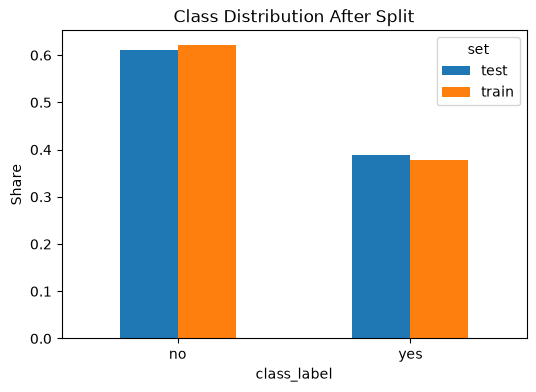

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Train rows: {len(X_train)}")
print(f"Test rows:  {len(X_test)}")

def class_distribution(labels, name):
    out = labels.value_counts().rename_axis("class").reset_index(name="count")
    out["share"] = out["count"] / len(labels)
    out["set"] = name
    return out[["set", "class", "count", "share"]]

dist = pd.concat([
    class_distribution(y_train, "train"),
    class_distribution(y_test, "test"),
], ignore_index=True)

display(dist)

ax = dist.assign(class_label=dist["class"].map({0: "no", 1: "yes"})).pivot(index="class_label", columns="set", values="share").plot.bar(figsize=(6, 4))
ax.set_title("Class Distribution After Split")
ax.set_ylabel("Share")
plt.xticks(rotation=0)
plt.show()

## 7. Build The Preprocessing Pipeline

A pipeline lets us keep preprocessing and the model together.

Why this matters:

- transformations learned from train data are reused on test data
- prevents accidental data leakage
- makes the code easier to reuse later

The `ColumnTransformer` says:

```text
numeric columns      -> impute median -> scale
categorical columns  -> impute missing -> one-hot encode
job_text             -> TF-IDF vectorize
```

In [11]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=3)),
])

text_vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_features=800,
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features + boolean_features),
        ("categorical", categorical_pipeline, categorical_features),
        ("text", text_vectorizer, "job_text"),
    ],
    remainder="drop",
    verbose_feature_names_out=True,
)

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and

## 8. Train Logistic Regression

The main model line is:

```python
LogisticRegression(...)
```

Important parameters here:

- `max_iter=2000`: allow enough optimization steps
- `class_weight="balanced"`: compensate for more `no` than `yes`
- `solver="liblinear"`: stable for small binary datasets
- `C=1.0`: regularization strength; smaller means stronger regularization
- `random_state=42`: reproducibility

The pipeline trains preprocessing and the model together.

In [12]:
log_reg = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    solver="liblinear",
    C=1.0,
    random_state=RANDOM_STATE,
)

model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("classifier", log_reg),
])

model.fit(X_train, y_train)

print("Model trained.")
model

Model trained.


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['job_text','can_apply_now','role_family_standard',...,'is_gurgaon_ncr', 'is_india','salary_available']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop

## 9. Predict Classes And Probabilities

There are two common prediction methods:

```python
model.predict(X_test)
```

Returns hard labels: `0` or `1`.

```python
model.predict_proba(X_test)[:, 1]
```

Returns probability of the positive class: `applied=yes`.

For JEDI, probability is more useful than only yes/no because we can rank jobs by confidence.

In [13]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

predictions = X_test.copy()
predictions["actual_applied"] = y_test.values
predictions["predicted_applied"] = y_pred
predictions["applied_probability"] = y_proba

display(predictions[["job_text", "actual_applied", "predicted_applied", "applied_probability"]].head(10))

,job_text,actual_applied,predicted_applied,applied_probability
14,"Addepar Software Engineer, Backend – AI Platform Backend / AI Platform mid Pune, India Backend; AI platform; data platform; investment t...",1,1,0.573374
123,"Xsolla Full-Stack Engineer Fullstack Unspecified / likely mid Montreal / Canada React, Go, microservices, Docker, Kubernetes [""react"",""g...",0,0,0.021408
260,Wahed Join Our Internship Program Software / Product Internship intern Any location / Mumbai possible Internship program; fintech produc...,1,1,0.902101
206,ARCLOGIQ Software Frontend Engineer | React.js | Next.js | React Native | Multilingual UI Frontend / React / Next.js Mid / 3+ years In o...,0,0,0.165465
278,"EarnIn Senior AI Dev Platform Engineer AI Platform / DevTools senior Bengaluru, India AI developer platform; tooling; backend services; ...",0,0,0.086019
111,"Noodle Senior Full-Stack Software Engineer Fullstack / Generative AI Agents Senior Remote, South Africa Next.js, TypeScript, Tailwind, O...",0,0,0.034881
255,Weekday Data Engineer (Hybrid) Data Engineering entry_level Bengaluru Data pipelines; SQL; Python; ETL; analytics; cloud data workflows ...,1,1,0.939598
95,"Netomi Backend Engineer II – Data Platform Backend / Data Platform SDE II Remote - India Backend, data platform, product engineering, ag...",0,0,0.330646
325,"Tresata Senior Frontend Engineer Frontend senior Bengaluru, Karnataka, India React; TypeScript; JavaScript; HTML5; CSS3; frontend compon...",0,0,0.032033
254,Weekday Backend Engineer Backend entry_level Bengaluru Backend APIs; databases; Python/Node/Java likely; product engineering; startup pa...,1,1,0.983326


## 10. Evaluation Metrics

Accuracy alone is not enough because the dataset is not perfectly balanced.

For JEDI, useful metrics are:

| Metric | What it means |
|---|---|
| Accuracy | overall correct predictions |
| Balanced accuracy | average recall across yes/no classes |
| Precision for yes | when model says apply, how often is it right? |
| Recall for yes | how many true apply-worthy jobs did it catch? |
| F1 | balance between precision and recall |
| ROC-AUC | ranking quality across thresholds |
| Average precision | PR-AUC, especially useful when positives are less common |
| Log loss | probability quality; lower is better |
| Brier score | probability calibration; lower is better |

Adequate first baseline targets for this dataset:

- beat majority baseline accuracy, around `62%`
- balanced accuracy above `0.65`
- ROC-AUC above `0.70`
- average precision clearly above positive rate, around `0.38`
- yes-class recall should not collapse; missing good jobs is costly


In [14]:
metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
    "precision_yes": precision_score(y_test, y_pred, zero_division=0),
    "recall_yes": recall_score(y_test, y_pred, zero_division=0),
    "f1_yes": f1_score(y_test, y_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_test, y_proba),
    "average_precision": average_precision_score(y_test, y_proba),
    "log_loss": log_loss(y_test, y_proba),
    "brier_score": brier_score_loss(y_test, y_proba),
}

metrics_df = pd.DataFrame([metrics]).T.rename(columns={0: "score"})
display(metrics_df)

print("Classification report:")
print(classification_report(y_test, y_pred, target_names=["no", "yes"], zero_division=0))

,score
accuracy,0.910448
balanced_accuracy,0.905722
precision_yes,0.884615
recall_yes,0.884615
f1_yes,0.884615
roc_auc,0.939962
average_precision,0.917937
log_loss,0.291022
brier_score,0.079910


Classification report:
              precision    recall  f1-score   support

          no       0.93      0.93      0.93        41
         yes       0.88      0.88      0.88        26

    accuracy                           0.91        67
   macro avg       0.91      0.91      0.91        67
weighted avg       0.91      0.91      0.91        67



,pred_no,pred_yes
actual_no,38,3
actual_yes,3,23


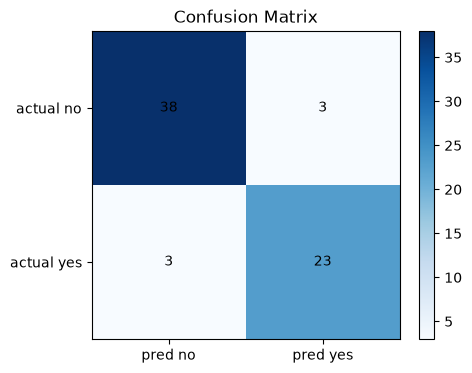

In [15]:
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm, index=["actual_no", "actual_yes"], columns=["pred_no", "pred_yes"])
display(cm_df)

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_title("Confusion Matrix")
ax.set_xticks([0, 1], labels=["pred no", "pred yes"])
ax.set_yticks([0, 1], labels=["actual no", "actual yes"])
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="black")
fig.colorbar(im, ax=ax)
plt.show()

## 11. Threshold Analysis

`model.predict` uses a default probability threshold of `0.5`.

But for job screening, we may want a different threshold:

- lower threshold: catches more good jobs, but more false positives
- higher threshold: fewer recommendations, but higher confidence

This table helps choose a threshold based on the tradeoff.

,threshold,predicted_yes_count,precision_yes,recall_yes,f1_yes,balanced_accuracy
0,0.20,38,0.631579,0.923077,0.750000,0.790807
1,0.25,35,0.685714,0.923077,0.786885,0.827392
2,0.30,30,0.800000,0.923077,0.857143,0.888368
3,0.35,28,0.857143,0.923077,0.888889,0.912758
4,0.40,27,0.888889,0.923077,0.905660,0.924953
5,0.45,26,0.884615,0.884615,0.884615,0.905722
6,0.50,26,0.884615,0.884615,0.884615,0.905722
7,0.55,24,0.916667,0.846154,0.880000,0.898687
8,0.60,23,0.913043,0.807692,0.857143,0.879456
9,0.65,23,0.913043,0.807692,0.857143,0.879456


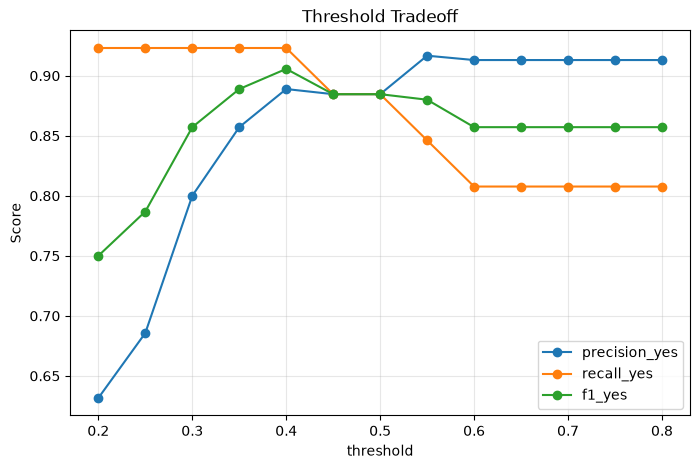

In [16]:
threshold_rows = []
for threshold in np.arange(0.20, 0.81, 0.05):
    pred_at_threshold = (y_proba >= threshold).astype(int)
    threshold_rows.append({
        "threshold": round(float(threshold), 2),
        "predicted_yes_count": int(pred_at_threshold.sum()),
        "precision_yes": precision_score(y_test, pred_at_threshold, zero_division=0),
        "recall_yes": recall_score(y_test, pred_at_threshold, zero_division=0),
        "f1_yes": f1_score(y_test, pred_at_threshold, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_test, pred_at_threshold),
    })

threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df)

ax = threshold_df.plot(x="threshold", y=["precision_yes", "recall_yes", "f1_yes"], figsize=(8, 5), marker="o")
ax.set_title("Threshold Tradeoff")
ax.set_ylabel("Score")
ax.grid(True, alpha=0.3)
plt.show()

## 12. Cross-Validation

A single train/test split can be noisy because the dataset is still small.

Cross-validation repeats evaluation across multiple splits and gives a more stable view.

Here we use `StratifiedKFold` so each fold keeps the yes/no ratio roughly similar.

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
}

cv_results = cross_validate(
    model,
    X,
    y,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    return_train_score=False,
)

cv_summary = []
for key, values in cv_results.items():
    if key.startswith("test_"):
        metric = key.replace("test_", "")
        cv_summary.append({
            "metric": metric,
            "mean": np.mean(values),
            "std": np.std(values),
            "fold_scores": np.round(values, 3),
        })

cv_summary = pd.DataFrame(cv_summary).sort_values("metric")
display(cv_summary)

,metric,mean,std,fold_scores
0,accuracy,0.873225,0.029040,"[0.836, 0.864, 0.924, 0.879, 0.864]"
6,average_precision,0.897248,0.044903,"[0.868, 0.909, 0.978, 0.85, 0.881]"
1,balanced_accuracy,0.862889,0.036492,"[0.81, 0.867, 0.923, 0.863, 0.851]"
4,f1,0.829553,0.043536,"[0.766, 0.83, 0.902, 0.833, 0.816]"
2,precision,0.846074,0.034541,"[0.857, 0.786, 0.885, 0.87, 0.833]"
3,recall,0.818462,0.078350,"[0.692, 0.88, 0.92, 0.8, 0.8]"
5,roc_auc,0.922904,0.031397,"[0.93, 0.896, 0.979, 0.891, 0.92]"


## 13. Inspect What The Model Learned

Logistic regression has coefficients.

A positive coefficient pushes the model toward `applied=yes`.

A negative coefficient pushes the model toward `applied=no`.

This is one reason logistic regression is a strong first model: we can inspect it.

In [18]:
feature_names = model.named_steps["preprocess"].get_feature_names_out()
coefficients = model.named_steps["classifier"].coef_[0]

coef_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients,
})

top_positive = coef_df.sort_values("coefficient", ascending=False).head(25)
top_negative = coef_df.sort_values("coefficient", ascending=True).head(25)

print("Top features pushing toward applied=yes")
display(top_positive)

print("Top features pushing toward applied=no")
display(top_negative)

Top features pushing toward applied=yes


,feature,coefficient
28,categorical__seniority_standard_new_grad,1.053289
36,categorical__employment_type_standard_unknown,0.820578
58,categorical__location_bucket_global_remote,0.801096
89,categorical__freshness_Reposted 1 month ago,0.750241
12,categorical__role_family_standard_backend,0.694206
61,categorical__location_bucket_india_remote,0.676694
67,categorical__experience_min_bucket_1,0.598717
24,categorical__seniority_standard_intern,0.576480
25,categorical__seniority_standard_junior,0.533371
343,text__engineering,0.517997


Top features pushing toward applied=no


,feature,coefficient
0,numeric__experience_min_years,-1.692068
77,categorical__freshness_2 months ago,-0.869327
71,categorical__experience_min_bucket_unknown,-0.804127
39,categorical__work_mode_standard_hybrid,-0.768034
29,categorical__seniority_standard_senior,-0.732601
30,categorical__seniority_standard_staff,-0.648404
60,categorical__location_bucket_india_other,-0.620194
27,categorical__seniority_standard_mid,-0.616195
34,categorical__employment_type_standard_full_time,-0.566886
446,text__go,-0.542744


## 14. Parameter Options We Could Try

Logistic regression has several useful knobs.

| Parameter | Meaning | Common values |
|---|---|---|
| `C` | inverse regularization strength | `0.01`, `0.1`, `1`, `10` |
| `penalty` | type of regularization | `"l2"`, `"l1"`, `"elasticnet"`, `None` |
| `solver` | optimization algorithm | `"liblinear"`, `"lbfgs"`, `"saga"` |
| `class_weight` | class imbalance handling | `None`, `"balanced"` |
| `max_iter` | maximum optimization iterations | `500`, `1000`, `2000` |

Practical rules:

- use `class_weight="balanced"` when positives are less common
- reduce `C` if the model overfits
- increase `max_iter` if convergence warnings appear
- use `solver="liblinear"` for small binary datasets
- use `solver="saga"` if trying `l1` or `elasticnet` with larger feature spaces


In [19]:
parameter_grid_notes = pd.DataFrame([
    {"experiment": "stronger regularization", "change": "C=0.1", "why": "reduce overfitting"},
    {"experiment": "weaker regularization", "change": "C=10", "why": "allow stronger feature effects"},
    {"experiment": "no class weighting", "change": "class_weight=None", "why": "see if balanced weighting is helping"},
    {"experiment": "sparse feature selection", "change": "penalty='l1', solver='liblinear'", "why": "force many coefficients to zero"},
    {"experiment": "more text features", "change": "TfidfVectorizer(max_features=1500)", "why": "capture more title/skill vocabulary"},
    {"experiment": "simpler text", "change": "ngram_range=(1, 1)", "why": "reduce sparse phrase features"},
])

display(parameter_grid_notes)

,experiment,change,why
0,stronger regularization,C=0.1,reduce overfitting
1,weaker regularization,C=10,allow stronger feature effects
2,no class weighting,class_weight=None,see if balanced weighting is helping
3,sparse feature selection,"penalty='l1', solver='liblinear'",force many coefficients to zero
4,more text features,TfidfVectorizer(max_features=1500),capture more title/skill vocabulary
5,simpler text,"ngram_range=(1, 1)",reduce sparse phrase features


## 15. Mini Hyperparameter Comparison

We will not over-optimize yet. The dataset is small.

But we can compare a few `C` values to see whether stronger/weaker regularization helps.

In [20]:
comparison_rows = []

for C in [0.05, 0.1, 0.5, 1.0, 2.0, 10.0]:
    candidate = Pipeline(steps=[
        ("preprocess", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            solver="liblinear",
            C=C,
            random_state=RANDOM_STATE,
        )),
    ])
    scores = cross_validate(
        candidate,
        X,
        y,
        cv=cv,
        scoring={"f1": "f1", "roc_auc": "roc_auc", "average_precision": "average_precision", "balanced_accuracy": "balanced_accuracy"},
        n_jobs=-1,
    )
    comparison_rows.append({
        "C": C,
        "f1_mean": scores["test_f1"].mean(),
        "roc_auc_mean": scores["test_roc_auc"].mean(),
        "average_precision_mean": scores["test_average_precision"].mean(),
        "balanced_accuracy_mean": scores["test_balanced_accuracy"].mean(),
    })

comparison_df = pd.DataFrame(comparison_rows).sort_values("average_precision_mean", ascending=False)
display(comparison_df)

,C,f1_mean,roc_auc_mean,average_precision_mean,balanced_accuracy_mean
5,10.00,0.831121,0.921411,0.902724,0.864143
4,2.00,0.836888,0.922326,0.899574,0.869328
3,1.00,0.829553,0.922904,0.897248,0.862889
2,0.50,0.823009,0.922717,0.896722,0.858011
1,0.10,0.823832,0.921208,0.894041,0.857704
0,0.05,0.820939,0.918116,0.889142,0.855265


## 16. What Counts As Good Enough?

For this first JEDI classifier, we should be pragmatic.

The dataset has only 331 labeled rows. So we are not expecting a production-perfect model.

A useful first logistic regression should:

1. beat majority baseline accuracy
2. have ROC-AUC above `0.70`
3. have average precision meaningfully above the positive rate
4. not destroy recall for `yes`
5. have interpretable coefficients that make sense

For JEDI, false negatives are painful because they hide good jobs. False positives waste time but are less catastrophic. So we may prefer a threshold with decent recall, then rank by probability.

In [21]:
majority_baseline_accuracy = max(y_test.mean(), 1 - y_test.mean())
positive_rate_test = y_test.mean()

quality_check = pd.DataFrame([
    {
        "check": "beats majority baseline accuracy",
        "baseline_or_target": majority_baseline_accuracy,
        "model_score": metrics["accuracy"],
        "pass": metrics["accuracy"] > majority_baseline_accuracy,
    },
    {
        "check": "balanced accuracy above 0.65",
        "baseline_or_target": 0.65,
        "model_score": metrics["balanced_accuracy"],
        "pass": metrics["balanced_accuracy"] >= 0.65,
    },
    {
        "check": "ROC-AUC above 0.70",
        "baseline_or_target": 0.70,
        "model_score": metrics["roc_auc"],
        "pass": metrics["roc_auc"] >= 0.70,
    },
    {
        "check": "average precision above positive rate",
        "baseline_or_target": positive_rate_test,
        "model_score": metrics["average_precision"],
        "pass": metrics["average_precision"] > positive_rate_test,
    },
    {
        "check": "yes recall above 0.60",
        "baseline_or_target": 0.60,
        "model_score": metrics["recall_yes"],
        "pass": metrics["recall_yes"] >= 0.60,
    },
])

display(quality_check)

,check,baseline_or_target,model_score,pass
0,beats majority baseline accuracy,0.61194,0.910448,True
1,balanced accuracy above 0.65,0.65000,0.905722,True
2,ROC-AUC above 0.70,0.70000,0.939962,True
3,average precision above positive rate,0.38806,0.917937,True
4,yes recall above 0.60,0.60000,0.884615,True


## 17. Save Test Predictions For Review

Model scores are not enough. We should inspect mistakes.

The saved file lets us manually review:

- high-confidence false positives
- high-confidence false negatives
- borderline rows near the threshold

This is how we improve the dataset and feature rules.

In [22]:
review_cols = [
    "company_name",
    "role_title",
    "role_family_standard",
    "seniority_standard",
    "location_bucket",
    "work_mode_standard",
    "employment_type_standard",
    "experience_min_years",
    "salary_midpoint",
    "skills_or_requirements",
]

test_review = df.loc[X_test.index, review_cols + ["applied"]].copy()
test_review["actual_applied_binary"] = y_test.values
test_review["predicted_applied_binary"] = y_pred
test_review["applied_probability"] = y_proba
test_review["error_type"] = np.select(
    [
        (test_review["actual_applied_binary"] == 1) & (test_review["predicted_applied_binary"] == 0),
        (test_review["actual_applied_binary"] == 0) & (test_review["predicted_applied_binary"] == 1),
    ],
    ["false_negative", "false_positive"],
    default="correct",
)

OUTPUT_PATH = Path("../../data/jedi_logistic_regression_test_predictions.csv")
test_review.sort_values("applied_probability", ascending=False).to_csv(OUTPUT_PATH, index=False)

print(f"Saved: {OUTPUT_PATH}")
display(test_review.sort_values("applied_probability", ascending=False).head(15))

Saved: data\jedi_logistic_regression_test_predictions.csv


,company_name,role_title,role_family_standard,seniority_standard,location_bucket,work_mode_standard,employment_type_standard,experience_min_years,salary_midpoint,skills_or_requirements,applied,actual_applied_binary,predicted_applied_binary,applied_probability,error_type
202,Patronus,Full stack Engineer (AI & Data Pipelines),fullstack,junior,bengaluru,onsite,full_time,1.0,1350000,javascript; react; node.js; rest apis; databases; git; deployment basics; llms; agentic ai; sql; data pipelines; security fundamentals; ...,yes,1,1,0.989484,correct
4,Energy Exemplar,Associate Software Engineer - Python,backend,entry_level,bengaluru,unknown,full_time,0.0,1025000,Python; algorithms; product development; possible data/optimization systems,yes,1,1,0.988261,correct
286,TopGrep Tech,Software Engineer Intern to hire,fullstack,intern,bengaluru,onsite,internship,0.0,225000,JavaScript; ReactJS; MySQL/Mongo/PostgreSQL; Azure; AI; Docker; Jenkins; Kubernetes; DataScience; ML/Ops,yes,1,1,0.984700,correct
308,Lokal App,Backend SDE-1,backend,entry_level,bengaluru,onsite,full_time,0.0,1000000,Backend development; Python; Java; JavaScript; SQL/NoSQL databases; API design; product engineering,yes,1,1,0.983623,correct
254,Weekday,Backend Engineer,backend,entry_level,bengaluru,onsite,full_time,0.0,1200000,Backend APIs; databases; Python/Node/Java likely; product engineering; startup pace,yes,1,1,0.983326,correct
172,360customizer,Backend Engineer,backend,junior,pune,onsite,full_time,1.0,1350000,backend fundamentals; rest apis; databases; sql; git; debugging; code quality; team collaboration,yes,1,1,0.982916,correct
209,ParallelDots,Machine Learning Engineer,ml_ai,intern,india_remote,remote,full_time,0.0,1350000,python; machine learning; llms; prompting; rag; data preprocessing; model evaluation; prompt engineering; ai product integration; learni...,yes,1,1,0.979275,correct
315,Origin,CVAT Annotation Intern,ml_ai,intern,bengaluru,onsite,internship,0.0,360000,CVAT; data annotation; machine learning data; AI delivery; computer vision datasets,no,0,1,0.973622,false_positive
267,Rubrik,Application Security Intern,backend,intern,bengaluru,onsite,internship,0.0,1500000,Python; Go; Scala; C/C++; JavaScript/TypeScript; CI/CD; Docker; Kubernetes; microservices; security,yes,1,1,0.972887,correct
258,Weekday,GTM Engineer,fullstack,entry_level,bengaluru,onsite,full_time,0.0,900000,Automation; scripting; integrations; AI tools; product workflows; light fullstack,yes,1,1,0.969131,correct


## 18. What To Learn From This Notebook

Key syntax to remember:

```python
train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
```

Splits data into train/test.

```python
ColumnTransformer([...])
```

Applies different preprocessing to different columns.

```python
Pipeline([("preprocess", preprocessor), ("classifier", LogisticRegression())])
```

Chains preprocessing and model into one object.

```python
model.fit(X_train, y_train)
```

Learns patterns from training data.

```python
model.predict(X_test)
model.predict_proba(X_test)[:, 1]
```

Predicts hard labels and probabilities.

Next model after this:

- preference score regression
- tree-based classifier
- calibrated probability model
- semi-supervised pseudo-labeling workflow

## 19. Student Deep Dive: How To Read This Logistic Regression Notebook

This section is written as a study guide. Read it after running the notebook once, then scroll back upward and connect each explanation to the code cell that produced it.

### What the notebook is trying to learn

The target is `applied`, converted into `target_applied` where `yes = 1` and `no = 0`. So the model is not learning a universal truth like "this is a good job for everyone". It is learning your past annotation behavior: given a job's title, company, role family, seniority, location, skills, salary, and normalized metadata, would you mark it as applied or not?

For this notebook we intentionally do not train on your personal score columns such as role preference score, location fit score, skills fit score, salary fit score, or overall preference score. Those are human judgment columns. If we included them, the model could cheat by learning your answer from your answer-like columns. This notebook asks a harder and cleaner question: can the raw job attributes predict the binary decision?

### Why each preprocessing step exists

- `df = pd.read_csv(DATA_PATH)` loads the prepared dataset. The prepared file already contains standardized helper fields like `role_family_standard`, `seniority_standard`, `location_bucket`, and `skills_array`.
- `target_applied = ...` converts text labels into numbers because scikit-learn classifiers expect numeric target values.
- `drop_columns` removes leakage and low-value metadata. Leakage means a column gives away the answer too directly. In this notebook, all preference score columns are leakage for the binary applied model.
- `source_platform` and `source_type` are dropped because we do not want the model to learn "jobs from source X are good". We want it to learn job quality and preference, not scraper origin.
- `text_source_columns` are merged into `job_text`. This gives the model one rich text field containing company, title, role family, seniority, location, and skills. Text models work better when related wording is available together.
- `categorical_features` are columns with a limited set of labels, such as `role_family_standard`, `work_mode_standard`, and `location_bucket`. These cannot be used as raw strings, so we one-hot encode them.
- `numeric_features` are continuous or ordered numbers, such as experience and salary. Logistic regression is sensitive to scale, so these are imputed and scaled.
- Boolean columns such as `is_bengaluru` and `is_india` are already 0/1 signals. They are included with the numeric block because they are numeric indicators.
- `train_test_split(..., stratify=y)` keeps the yes/no class ratio similar in train and test. Without stratification, a small dataset can accidentally create a test set with too many yes or too many no examples.
- `SimpleImputer(strategy='median')` fills missing numeric values using the training-set median. This avoids dropping rows and prevents the test set from influencing the training transformation.
- `StandardScaler()` changes numeric values into comparable scale. Example: salary may be in lakhs while `is_india` is only 0/1. Scaling prevents large raw numbers from dominating the optimization just because of unit size.
- `SimpleImputer(strategy='most_frequent')` fills missing categorical values with the most common category seen in training.
- `OneHotEncoder(handle_unknown='ignore', min_frequency=3)` converts categories into binary columns. `handle_unknown='ignore'` matters because future scraped jobs may contain a new city, company style, or employment label not seen during training. `min_frequency=3` prevents extremely rare categories from becoming fragile one-row features.
- `TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=800)` converts text into numbers. TF-IDF gives higher value to words that are meaningful in this dataset and lower value to words that appear everywhere. `(1, 2)` means it learns both single words like `backend` and two-word phrases like `software engineer`. `min_df=2` ignores words seen only once because one-off terms are usually noise in a small dataset.
- `ColumnTransformer(...)` applies the right preprocessing to the right column type and combines the output into one feature matrix.
- `Pipeline(...)` chains preprocessing and the model together. This is important because during cross-validation and testing, preprocessing is fit only on training data, reducing data leakage.
- `LogisticRegression(class_weight='balanced')` tells the model not to ignore the minority class. Your data has more `no` than `yes`, so class weighting prevents a lazy model that mostly predicts `no`.

### Logistic regression in plain language

Logistic regression learns one weight per feature. A positive weight pushes the model toward `applied=yes`; a negative weight pushes it toward `applied=no`. The weighted sum is then converted into a probability between 0 and 1. That is why this model is a strong first baseline: it is simple, fast, works well with sparse TF-IDF text, and its coefficients can be inspected.

### How to read the metrics

- Confusion matrix: the most concrete output. In this run it was `38 true no`, `3 false yes`, `3 false no`, and `23 true yes`. False yes means the model recommended applying when your label said no. False no means it missed a job you had labeled yes.
- Accuracy: total correct predictions. Here it is `0.910`, but accuracy alone is not enough because the dataset is about 62% no and 38% yes.
- Balanced accuracy: average of recall for both classes. Here it is `0.906`, which is more trustworthy than plain accuracy for class imbalance.
- Precision for yes: when the model says apply, how often is it right? Here it is `0.885`. High precision means fewer bad recommendations in your daily shortlist.
- Recall for yes: out of jobs you would apply to, how many did the model catch? Here it is `0.885`. High recall means fewer missed opportunities.
- F1 for yes: one number balancing precision and recall. Here it is `0.885`.
- ROC-AUC: ranking quality across thresholds. Here it is `0.940`, which means the model is good at ranking yes jobs above no jobs.
- Average precision: ranking quality focused on the positive class. Here it is `0.918`, useful because your application queue cares most about the best yes candidates.
- Log loss and Brier score: probability quality. Lower is better. They punish confident wrong predictions. Here log loss is `0.291` and Brier score is `0.080`, both reasonable for a first personal model.

### Interpreting this run

The held-out split looks strong: 61 out of 67 test rows were classified correctly. The model made only 3 false positives and 3 false negatives. That says the signal in your annotations is learnable.

However, cross-validation is more conservative: mean F1 is about `0.830`, balanced accuracy about `0.863`, and ROC-AUC about `0.923`. This means the single test score of `0.910` accuracy is probably a little optimistic. For project reporting, say the model is roughly in the high-0.80s on stable validation, not simply "91% accurate".

The threshold table is important. At threshold `0.50`, F1 is `0.885`. At threshold `0.40`, F1 improves to `0.906` and balanced accuracy improves to `0.925`. For this project, threshold `0.40` is a sensible first operating point because missing a good job is usually worse than reviewing one extra job. If you want a stricter shortlist, use a higher threshold like `0.55`.

The coefficient table also tells a story. The model is pushed toward yes by new-grad/intern/junior signals, backend/data-engineering signals, India and remote buckets, low experience buckets, and words like `ai`, `engineering`, and `software engineering`. It is pushed toward no by higher `experience_min_years`, senior/staff/mid labels, old freshness values, unknown/less-preferred locations, and heavier infra terms like Java microservices, Kubernetes, observability, and networking. This matches your stated early-career preference pattern.

Be careful with artifact-looking coefficients such as `employment_type_unknown` or `work_mode_unknown`. If those are predictive, it may mean some manually gathered good jobs had missing metadata. That is not a real-world preference; it is a data collection pattern. As the dataset grows, these should become less important.

### What action this suggests

Use logistic regression as the main interpretable baseline. Before production, add more borderline examples: decent jobs you still rejected and imperfect jobs you still liked. Those examples teach the model the boundary. Also try a grouped split by `near_duplicate_key` later, because similar listings across sources can make validation look better than real deployment.